In [1]:

import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Industrial IoT project environment ready!")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
Industrial IoT project environment ready!


In [2]:

import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)

# Generate sample sensor telemetry
n = 5000

timestamps = pd.date_range(
    start="2025-01-01",
    periods=n,
    freq="h"
)

vibration = np.random.normal(4.0, 0.9, n).clip(0.2, None)
temperature = np.random.normal(70, 8, n).clip(30, None)
voltage = np.random.normal(220, 7, n)
acoustic = np.random.normal(35, 6, n).clip(5, None)

# Simulated degradation signal
degradation = (
    0.20 * vibration
    + 0.018 * (temperature - 60)
    + 0.012 * acoustic
    + 0.003 * np.abs(voltage - 220)
    + np.random.normal(0, 0.25, n)
)

# Simulated remaining useful life (hours)
rul = np.clip(
    100 - 30 * degradation
    + np.random.normal(0, 30, n),
    0, 200
)

# Simulated probability of failure within 24 hours
failure_probability = 1 / (
    1 + np.exp(np.clip((rul - 24) / 12, -30, 30))
)

failure_24h = (
    np.random.rand(n) < failure_probability
).astype(int)

# Build dataset
df = pd.DataFrame({
    "timestamp": timestamps,
    "vibration": vibration,
    "spindle_temperature": temperature,
    "motor_voltage": voltage,
    "acoustic_noise": acoustic,
    "RUL_hours": rul,
    "failure_24h": failure_24h
})

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))


Dataset created successfully!
Dataset shape: (5000, 7)


,timestamp,vibration,spindle_temperature,motor_voltage,acoustic_noise,RUL_hours,failure_24h
0,2025-01-01 00:00:00,4.447043,66.609923,215.250537,34.139461,59.544787,0
1,2025-01-01 01:00:00,3.875562,66.372687,217.861504,34.804065,58.826184,0
2,2025-01-01 02:00:00,4.582920,55.634855,215.818333,35.385769,55.833680,0
3,2025-01-01 03:00:00,5.370727,67.359278,220.772926,40.681169,44.664163,0
4,2025-01-01 04:00:00,3.789262,75.862633,228.380250,30.516696,82.859242,0
5,2025-01-01 05:00:00,3.789277,59.806143,214.602705,29.921918,67.232894,0
6,2025-01-01 06:00:00,5.421292,78.387861,227.005743,42.419718,69.227378,0
7,2025-01-01 07:00:00,4.690691,73.902199,214.528295,32.224132,15.465762,0
8,2025-01-01 08:00:00,3.577473,64.126133,214.066610,27.421788,49.521013,0
9,2025-01-01 09:00:00,4.488304,68.867763,225.730162,32.089220,17.932505,1


In [3]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nFailure label distribution:")
print(df["failure_24h"].value_counts())

print("\nStatistical summary:")
display(df.describe().round(2))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   timestamp            5000 non-null   datetime64[ns]
 1   vibration            5000 non-null   float64       
 2   spindle_temperature  5000 non-null   float64       
 3   motor_voltage        5000 non-null   float64       
 4   acoustic_noise       5000 non-null   float64       
 5   RUL_hours            5000 non-null   float64       
 6   failure_24h          5000 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 273.6 KB

Missing values:
timestamp              0
vibration              0
spindle_temperature    0
motor_voltage          0
acoustic_noise         0
RUL_hours              0
failure_24h            0
dtype: int64

Failure label distribution:
failure_24h
0    4053
1     947
Name: count, dtype: int

,timestamp,vibration,spindle_temperature,motor_voltage,acoustic_noise,RUL_hours,failure_24h
count,5000,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,2025-04-15 03:29:59.999999744,4.01,69.92,220.07,35.10,57.83,0.19
min,2025-01-01 00:00:00,1.08,38.62,196.37,11.86,0.00,0.00
25%,2025-02-22 01:45:00,3.41,64.51,215.37,31.01,35.79,0.00
50%,2025-04-15 03:30:00,4.01,69.86,220.07,35.12,57.08,0.00
75%,2025-06-06 05:15:00,4.60,75.42,224.73,39.24,78.98,0.00
max,2025-07-28 07:00:00,7.53,98.23,244.00,61.87,178.01,1.00
std,NaN,0.90,8.08,6.99,6.02,30.80,0.39


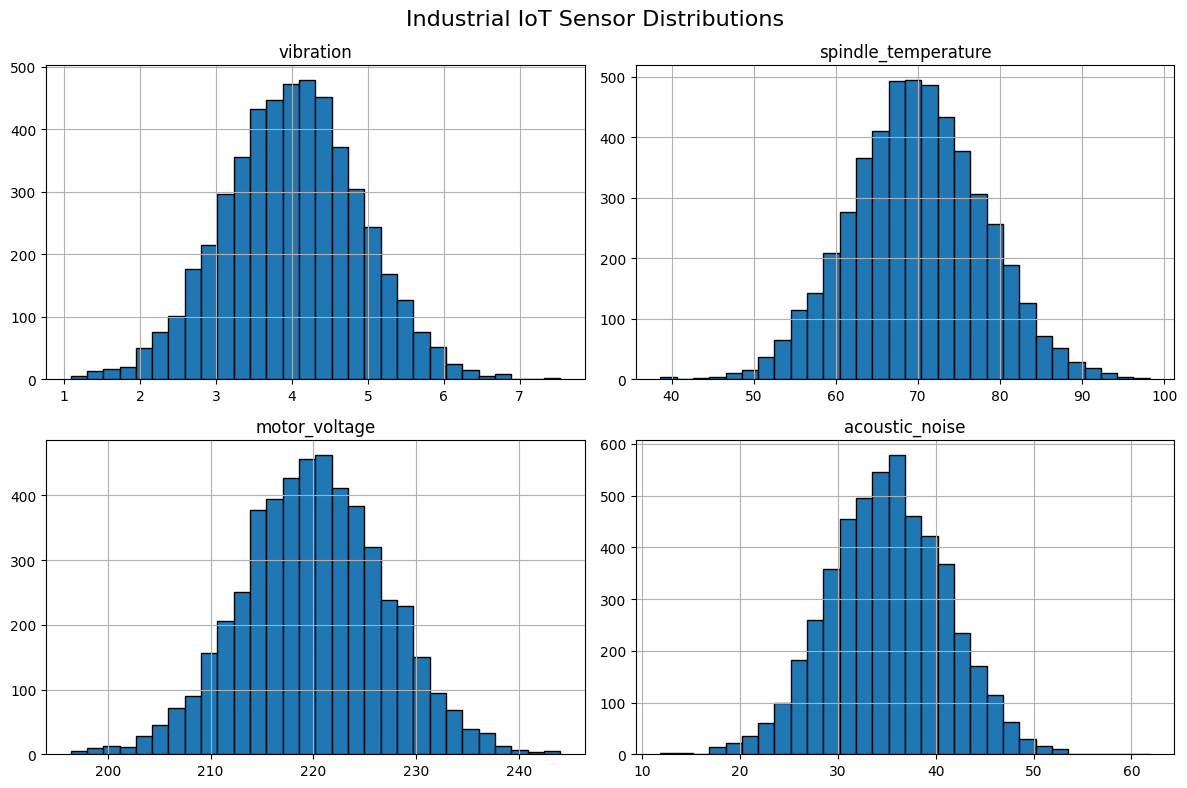

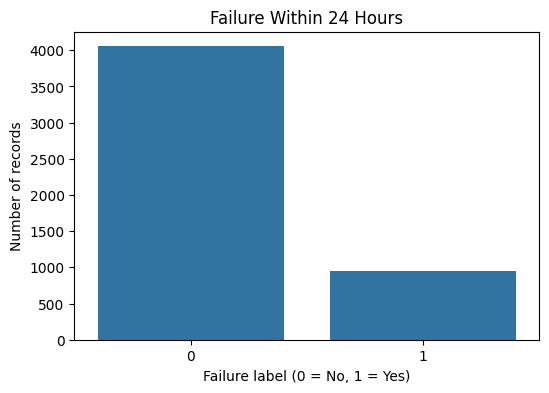

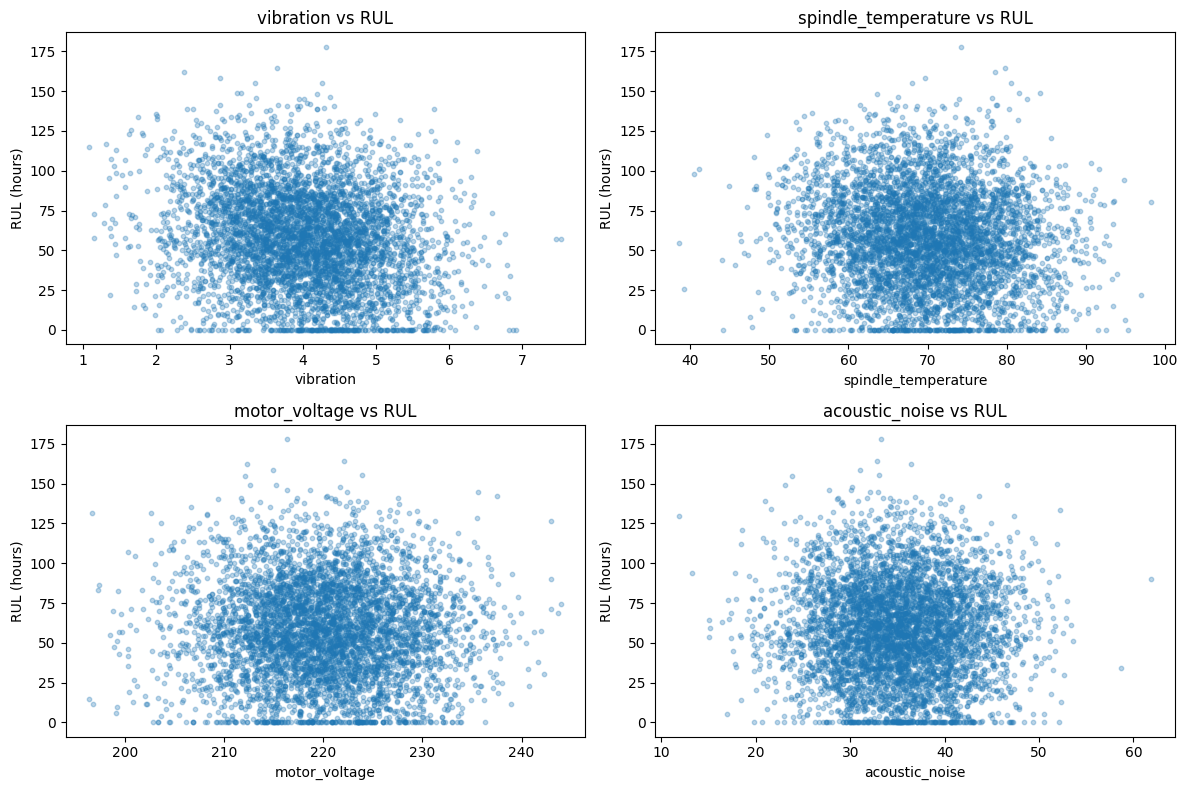

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sensor distributions
sensor_cols = [
    "vibration",
    "spindle_temperature",
    "motor_voltage",
    "acoustic_noise"
]

df[sensor_cols].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Industrial IoT Sensor Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# 2. Failure label distribution
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="failure_24h"
)

plt.title("Failure Within 24 Hours")
plt.xlabel("Failure label (0 = No, 1 = Yes)")
plt.ylabel("Number of records")
plt.show()

# 3. Sensor readings versus RUL
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(sensor_cols, axes.flatten()):
    ax.scatter(
        df[col],
        df["RUL_hours"],
        alpha=0.3,
        s=10
    )
    ax.set_xlabel(col)
    ax.set_ylabel("RUL (hours)")
    ax.set_title(f"{col} vs RUL")

plt.tight_layout()
plt.show()


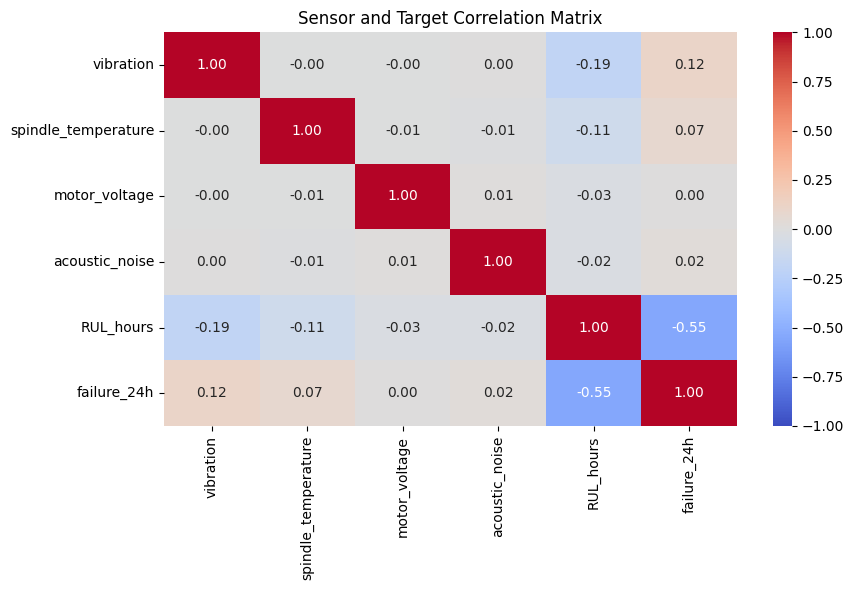

In [5]:

plt.figure(figsize=(9, 6))

correlation = df[
    sensor_cols + ["RUL_hours", "failure_24h"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Sensor and Target Correlation Matrix")
plt.tight_layout()
plt.show()


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Select sensor features only — exclude timestamp and targets
sensor_cols = [
    "vibration",
    "spindle_temperature",
    "motor_voltage",
    "acoustic_noise"
]

X = df[sensor_cols].copy()
y_rul = df["RUL_hours"].copy()
y_failure = df["failure_24h"].copy()

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Split data before fitting preprocessing steps
X_train, X_test, y_rul_train, y_rul_test = train_test_split(
    X, y_rul,
    test_size=0.20,
    random_state=42
)

# Use the same row indices for classification
y_failure_train = y_failure.loc[X_train.index]
y_failure_test = y_failure.loc[X_test.index]

# Fit preprocessing on training data only
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original number of sensor features:", X_train.shape[1])
print("Features after polynomial engineering:", X_train_processed.shape[1])
print("Training records:", X_train_processed.shape[0])
print("Testing records:", X_test_processed.shape[0])
print("Missing sensor values in training:", X_train.isna().sum().sum())
print("Preprocessing completed successfully!")


Original number of sensor features: 4
Features after polynomial engineering: 14
Training records: 4000
Testing records: 1000
Missing sensor values in training: 0
Preprocessing completed successfully!


LINEAR REGRESSION — RUL EVALUATION
----------------------------------------
Mean Absolute Error (MAE): 22.81 hours
Root Mean Squared Error (RMSE): 28.62 hours


,Actual_RUL,Predicted_RUL
0,53.574533,64.718373
1,83.628491,66.152624
2,35.851064,51.488832
3,46.068466,59.557875
4,36.634629,62.999949
5,0.000000,51.500254
6,64.577770,62.130168
7,53.602356,54.978929
8,43.395766,62.500532
9,60.342050,63.514603


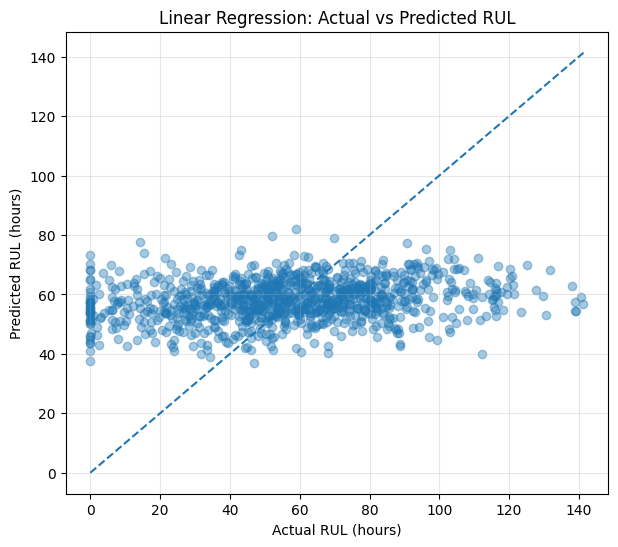

In [7]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Build the RUL regression pipeline
rul_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train the model
rul_model.fit(X_train, y_rul_train)

# Predict RUL on unseen test records
y_rul_pred = rul_model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_rul_test, y_rul_pred)
rmse = np.sqrt(mean_squared_error(y_rul_test, y_rul_pred))

print("LINEAR REGRESSION — RUL EVALUATION")
print("-" * 40)
print(f"Mean Absolute Error (MAE): {mae:.2f} hours")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} hours")

# Compare actual and predicted RUL
results = pd.DataFrame({
    "Actual_RUL": y_rul_test.values,
    "Predicted_RUL": y_rul_pred
})

display(results.head(10))

# Plot actual versus predicted values
plt.figure(figsize=(7, 6))
plt.scatter(
    y_rul_test,
    y_rul_pred,
    alpha=0.4
)

lower = min(y_rul_test.min(), y_rul_pred.min())
upper = max(y_rul_test.max(), y_rul_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual RUL (hours)")
plt.ylabel("Predicted RUL (hours)")
plt.title("Linear Regression: Actual vs Predicted RUL")
plt.grid(alpha=0.3)
plt.show()


In [8]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Build the failure prediction pipeline
failure_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using sensor features only
failure_model.fit(X_train, y_failure_train)

# Predicted probabilities
train_prob = failure_model.predict_proba(X_train)[:, 1]
test_prob = failure_model.predict_proba(X_test)[:, 1]

# Select a threshold using training data only
target_recall = 0.90
precision_train, recall_train, thresholds = precision_recall_curve(
    y_failure_train, train_prob
)

valid = np.where(recall_train[:-1] >= target_recall)[0]

if len(valid) > 0:
    tuned_threshold = float(thresholds[valid[-1]])
else:
    f1_train = (
        2 * precision_train * recall_train
        / np.maximum(precision_train + recall_train, 1e-12)
    )
    tuned_threshold = float(
        thresholds[np.argmax(f1_train[:-1])]
    )

print("Failure model training completed!")
print(f"Default threshold: 0.50")
print(f"Tuned threshold: {tuned_threshold:.4f}")
print(f"Target training recall: {target_recall:.2f}")


Failure model training completed!
Default threshold: 0.50
Tuned threshold: 0.4077
Target training recall: 0.90


HELD-OUT TEST SET RESULTS


,Threshold,Value,Accuracy,Precision,Recall,F1
0,Default,0.5000,0.557,0.2208,0.6057,0.3237
1,Recall-tuned,0.4077,0.316,0.1862,0.8629,0.3063


ROC-AUC: 0.5969

Default confusion matrix
[[451 374]
 [ 69 106]]
Rows = actual classes [0, 1]
Columns = predicted classes [0, 1]

Recall-tuned confusion matrix
[[165 660]
 [ 24 151]]
Rows = actual classes [0, 1]
Columns = predicted classes [0, 1]


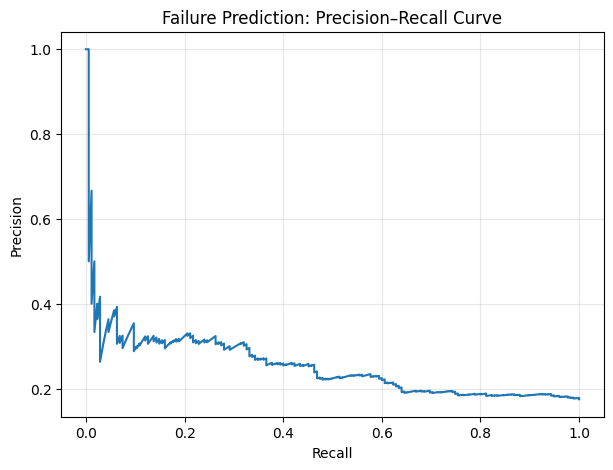

In [9]:

def evaluate_threshold(y_true, probabilities, threshold, name):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Threshold": name,
        "Value": round(float(threshold), 4),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Confusion Matrix": confusion_matrix(
            y_true, predictions
        )
    }

default_results = evaluate_threshold(
    y_failure_test, test_prob, 0.50, "Default"
)

tuned_results = evaluate_threshold(
    y_failure_test, test_prob, tuned_threshold, "Recall-tuned"
)

comparison = pd.DataFrame([
    {k: v for k, v in default_results.items()
     if k != "Confusion Matrix"},
    {k: v for k, v in tuned_results.items()
     if k != "Confusion Matrix"}
])

print("HELD-OUT TEST SET RESULTS")
display(comparison.round(4))

print("ROC-AUC:", round(
    roc_auc_score(y_failure_test, test_prob), 4
))

for result in [default_results, tuned_results]:
    print(f"\n{result['Threshold']} confusion matrix")
    print(result["Confusion Matrix"])
    print("Rows = actual classes [0, 1]")
    print("Columns = predicted classes [0, 1]")

# Precision-recall curve
p, r, _ = precision_recall_curve(
    y_failure_test, test_prob
)

plt.figure(figsize=(7, 5))
plt.plot(r, p)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Failure Prediction: Precision–Recall Curve")
plt.grid(alpha=0.3)
plt.show()


In [10]:

import json
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score
)

# Save trained models
joblib.dump(rul_model, "p1_rul_regressor.joblib")
joblib.dump(failure_model, "p1_failure_classifier.joblib")

# Build the evaluation report from executed results
report = {
    "project": "P1 - Industrial IoT Failure Prediction",
    "data_source": "Synthetic demonstration dataset",
    "dataset_rows": int(len(df)),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "sensor_features": sensor_cols,
    "rul_regression": {
        "MAE_hours": float(
            mean_absolute_error(y_rul_test, y_rul_pred)
        ),
        "RMSE_hours": float(
            np.sqrt(mean_squared_error(y_rul_test, y_rul_pred))
        )
    },
    "failure_classification": {
        "ROC_AUC": float(
            roc_auc_score(y_failure_test, test_prob)
        ),
        "default_threshold": {
            k: v for k, v in default_results.items()
            if k != "Confusion Matrix"
        },
        "recall_tuned_threshold": {
            k: v for k, v in tuned_results.items()
            if k != "Confusion Matrix"
        },
        "default_confusion_matrix":
            default_results["Confusion Matrix"].tolist(),
        "tuned_confusion_matrix":
            tuned_results["Confusion Matrix"].tolist()
    },
    "limitations": [
        "Synthetic data; not real industrial telemetry.",
        "Failure classifier has limited discrimination.",
        "Random train/test split; chronological or machine-held-out validation is recommended."
    ]
}

with open("p1_evaluation_report.json", "w") as f:
    json.dump(report, f, indent=2)

# Save threshold comparison
comparison.to_csv("p1_threshold_comparison.csv", index=False)

print("Saved RUL model: p1_rul_regressor.joblib")
print("Saved failure model: p1_failure_classifier.joblib")
print("Saved evaluation report: p1_evaluation_report.json")
print("Saved threshold comparison: p1_threshold_comparison.csv")

print("\nRUL metrics:")
print(report["rul_regression"])

print("\nFailure ROC-AUC:")
print(report["failure_classification"]["ROC_AUC"])


Saved RUL model: p1_rul_regressor.joblib
Saved failure model: p1_failure_classifier.joblib
Saved evaluation report: p1_evaluation_report.json
Saved threshold comparison: p1_threshold_comparison.csv

RUL metrics:
{'MAE_hours': 22.812248775880544, 'RMSE_hours': 28.619136379518746}

Failure ROC-AUC:
0.5968761904761904


In [12]:

from google.colab import files

files.download("p1_evaluation_report.json")
files.download("p1_threshold_comparison.csv")
files.download("p1_rul_regressor.joblib")
files.download("p1_failure_classifier.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

import os

required_files = [
    "p1_evaluation_report.json",
    "p1_threshold_comparison.csv",
    "p1_rul_regressor.joblib",
    "p1_failure_classifier.joblib"
]

for filename in required_files:
    if os.path.exists(filename):
        print(f"✅ FOUND: {filename} ({os.path.getsize(filename):,} bytes)")
    else:
        print(f"❌ MISSING: {filename}")


✅ FOUND: p1_evaluation_report.json (1,374 bytes)
✅ FOUND: p1_threshold_comparison.csv (206 bytes)
✅ FOUND: p1_rul_regressor.joblib (2,417 bytes)
✅ FOUND: p1_failure_classifier.joblib (2,625 bytes)


In [14]:

import joblib
import pandas as pd

# Reload saved models
loaded_rul_model = joblib.load("p1_rul_regressor.joblib")
loaded_failure_model = joblib.load("p1_failure_classifier.joblib")

# One new simulated sensor observation
new_machine = pd.DataFrame([{
    "vibration": 4.2,
    "spindle_temperature": 72.0,
    "motor_voltage": 219.0,
    "acoustic_noise": 36.0
}])

# Predict remaining useful life
predicted_rul = loaded_rul_model.predict(new_machine)[0]

# Predict probability of failure within 24 hours
failure_probability = loaded_failure_model.predict_proba(
    new_machine
)[0, 1]

# Use the threshold selected earlier
failure_prediction = int(
    failure_probability >= tuned_threshold
)

print("NEW SENSOR RECORD — MODEL TEST")
print("-" * 40)
print(f"Predicted RUL: {predicted_rul:.2f} hours")
print(f"Failure probability: {failure_probability:.2%}")
print(f"Threshold used: {tuned_threshold:.4f}")
print(f"Predicted failure class: {failure_prediction}")
print("0 = No failure predicted within 24 hours")
print("1 = Failure risk flagged within 24 hours")


NEW SENSOR RECORD — MODEL TEST
----------------------------------------
Predicted RUL: 55.60 hours
Failure probability: 54.29%
Threshold used: 0.4077
Predicted failure class: 1
0 = No failure predicted within 24 hours
1 = Failure risk flagged within 24 hours
